# Свертка матриц

https://ru.wikipedia.org/wiki/%D0%AF%D0%B4%D1%80%D0%BE_%D1%81%D0%B2%D0%B5%D1%80%D1%82%D0%BA%D0%B8

https://neerc.ifmo.ru/wiki/index.php?title=%D0%A4%D0%B0%D0%B9%D0%BB:Convolution_example.png

https://neerc.ifmo.ru/wiki/index.php?title=%D0%A1%D0%B2%D0%B5%D1%80%D1%82%D0%BE%D1%87%D0%BD%D1%8B%D0%B5_%D0%BD%D0%B5%D0%B9%D1%80%D0%BE%D0%BD%D0%BD%D1%8B%D0%B5_%D1%81%D0%B5%D1%82%D0%B8#.D0.A1.D0.B2.D0.B5.D1.80.D1.82.D0.BA.D0.B0



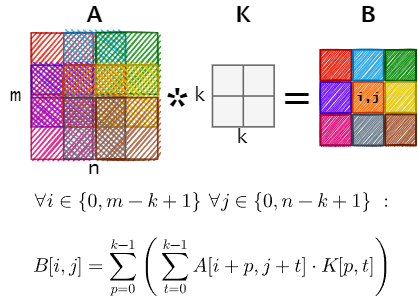

In [16]:
from PIL import Image
from urllib.request import urlopen
import numpy as np

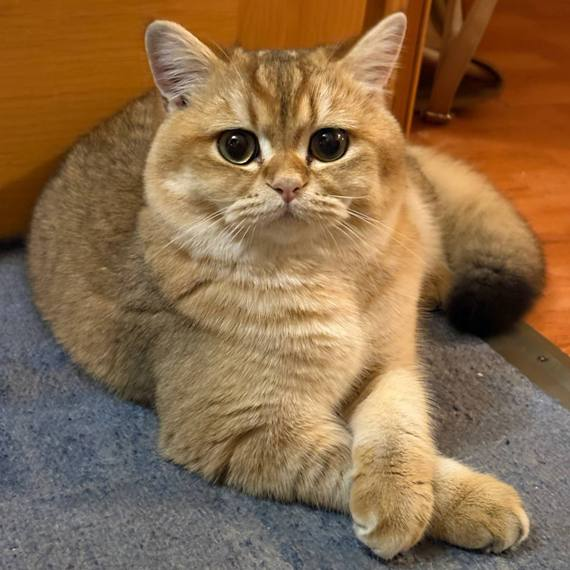

In [17]:
url = "https://ctlab.itmo.ru/~aivanov/bi_2026/cat.jpg"
image = Image.open(urlopen(url))

display(image)

In [18]:
def transform(image, kernel):
  sz = image.size[0]
  offset = kernel.shape[0]-1
  r, g, b = image.split()

  red = np.array(r)
  green = np.array(g)
  blue = np.array(b)

  r_transformed = np.zeros(shape=(sz-offset, sz-offset), dtype=np.uint8)
  g_transformed = np.zeros(shape=(sz-offset, sz-offset), dtype=np.uint8)
  b_transformed = np.zeros(shape=(sz-offset, sz-offset), dtype=np.uint8)

  for i in range(sz-offset):
    for j in range(sz-offset):
      tmp_r = 0
      tmp_g = 0
      tmp_b = 0

      tmp_r = np.sum(
        red[i:i+offset+1, j:j+offset+1] * kernel
      )
      tmp_g = np.sum(
        green[i:i+offset+1, j:j+offset+1] * kernel
      )
      tmp_b = np.sum(
        blue[i:i+offset+1, j:j+offset+1] * kernel
      )

      r_transformed[i][j] = max(min(tmp_r, 255), 0)
      g_transformed[i][j] = max(min(tmp_g, 255), 0)
      b_transformed[i][j] = max(min(tmp_b, 255), 0)

      r_transformed[i][j] = max(min(tmp_r, 255), 0)
      g_transformed[i][j] = max(min(tmp_g, 255), 0)
      b_transformed[i][j] = max(min(tmp_b, 255), 0)

  return Image.merge("RGB", [Image.fromarray(r_transformed), Image.fromarray(g_transformed), Image.fromarray(b_transformed)])

In [19]:
kernel_0 = np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]])

print(kernel_0)

[[0 0 0]
 [0 1 0]
 [0 0 0]]


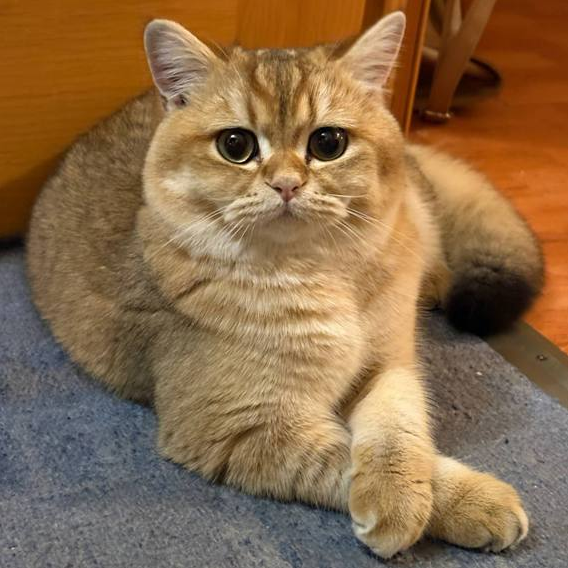

In [20]:
display(transform(image, kernel_0))

In [21]:
kernel_1 = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]])

print(kernel_1)

[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]


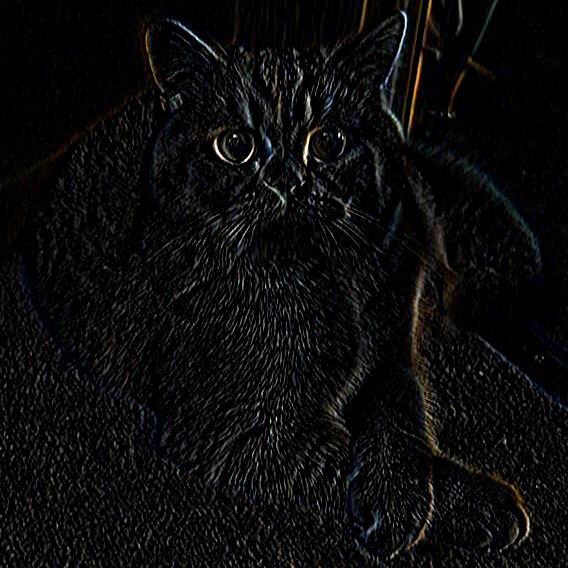

In [22]:
display(transform(image, kernel_1))

In [23]:
kernel_2 = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]])

print(kernel_2)

[[ 0 -1  0]
 [-1  4 -1]
 [ 0 -1  0]]


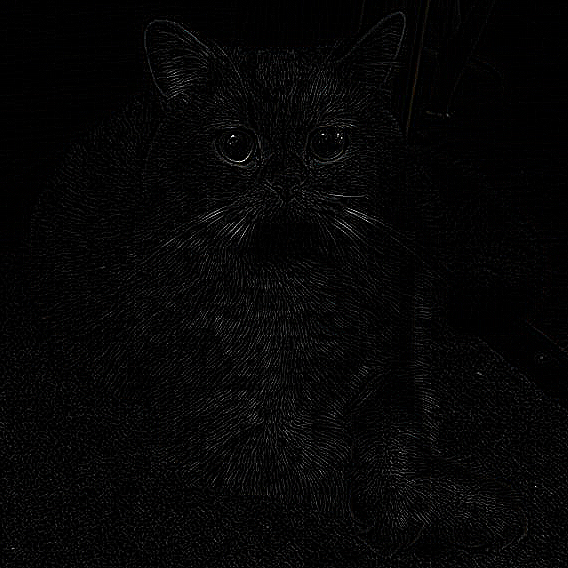

In [24]:
display(transform(image, kernel_2))

In [25]:
kernel_3 = np.array([[1, 1, 1], [1, 1, 1], [1, 1, 1]]) / 9

print(kernel_3)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


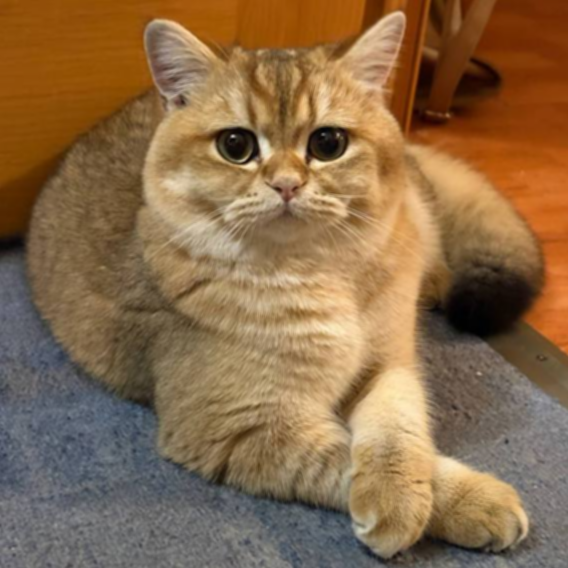

In [26]:
display(transform(image, kernel_3))

In [27]:
kernel_4 = np.array([[2, 2, 2], [2, 1, 2], [2, 2, 2]]) / 17

print(kernel_4)

[[0.11764706 0.11764706 0.11764706]
 [0.11764706 0.05882353 0.11764706]
 [0.11764706 0.11764706 0.11764706]]


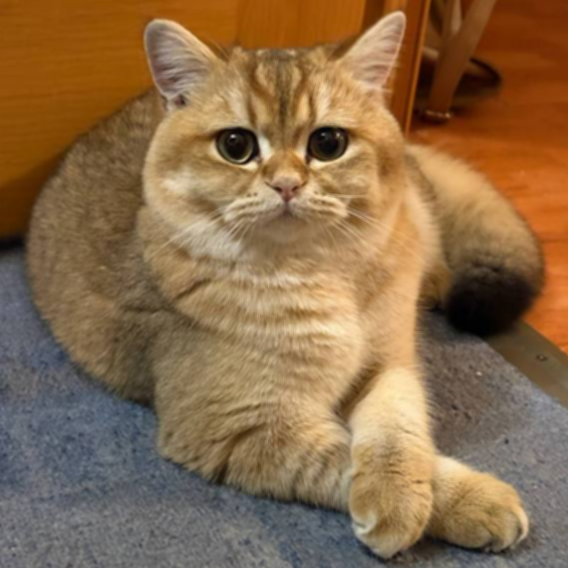

In [28]:
display(transform(image, kernel_4))

In [29]:
kernel_5 = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]])

print(kernel_5)

[[-2 -1  0]
 [-1  1  1]
 [ 0  1  2]]


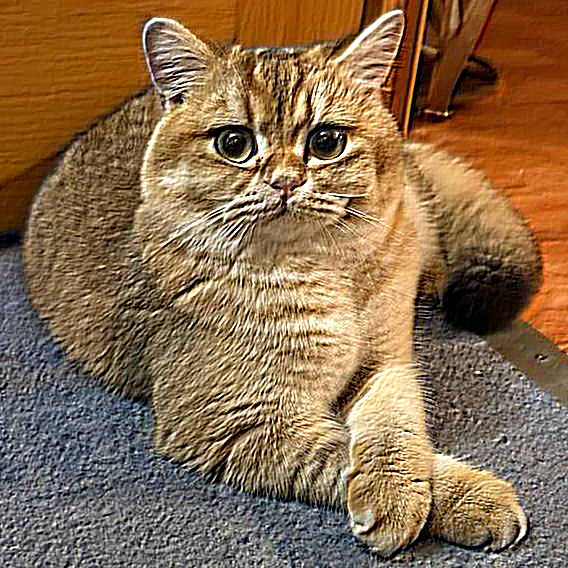

In [30]:
display(transform(image, kernel_5))

In [31]:
kernel_6 = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])

print(kernel_6)

[[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]


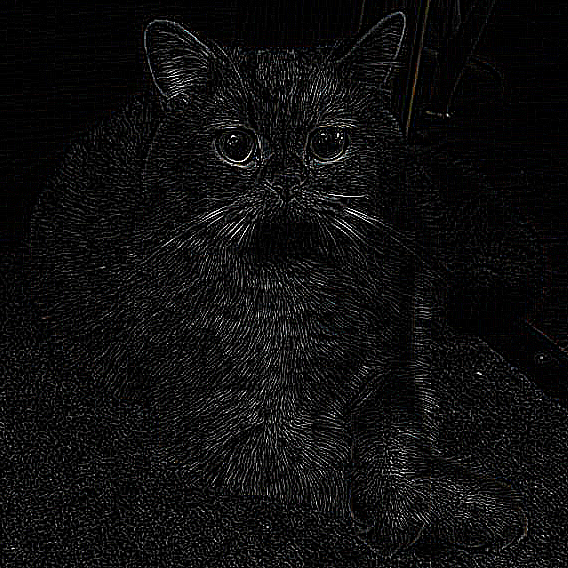

In [32]:
display(transform(image, kernel_6))

In [33]:
kernel_7 = np.array([[-1, -1, -1, -1, -1], [-1,  3,  3,  3, -1], [-1,  3, 11,  3, -1], [-1,  3,  3,  3, -1], [-1, -1, -1, -1, -1]]) / 15
print(kernel_7)


[[-0.06666667 -0.06666667 -0.06666667 -0.06666667 -0.06666667]
 [-0.06666667  0.2         0.2         0.2        -0.06666667]
 [-0.06666667  0.2         0.73333333  0.2        -0.06666667]
 [-0.06666667  0.2         0.2         0.2        -0.06666667]
 [-0.06666667 -0.06666667 -0.06666667 -0.06666667 -0.06666667]]


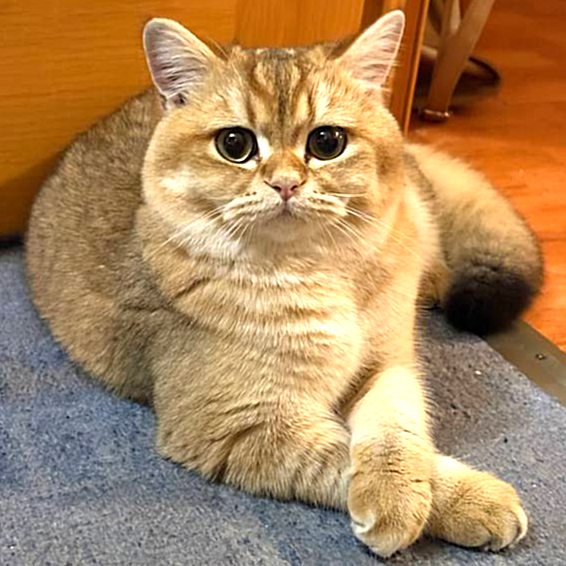

In [34]:
display(transform(image, kernel_7))

In [35]:
kernel_8 = np.array([[0, 0, 1, 0, 0], [0, 0, 1, 0, 0], [1, 1, 4, 1, 1], [0, 0, 1, 0, 0], [0, 0, 1, 0, 0]]) / 12

print(kernel_8)

[[0.         0.         0.08333333 0.         0.        ]
 [0.         0.         0.08333333 0.         0.        ]
 [0.08333333 0.08333333 0.33333333 0.08333333 0.08333333]
 [0.         0.         0.08333333 0.         0.        ]
 [0.         0.         0.08333333 0.         0.        ]]


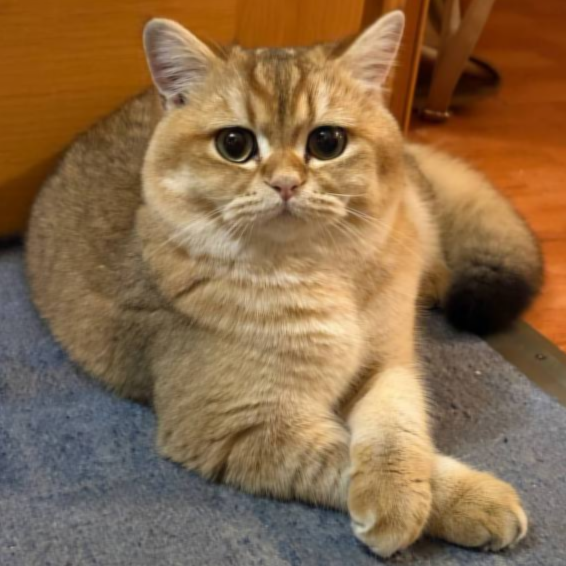

In [36]:
display(transform(image, kernel_8))

In [37]:
kernel_9 = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]])

print(kernel_9)

[[ 1  1  1]
 [ 0  0  0]
 [-1 -1 -1]]


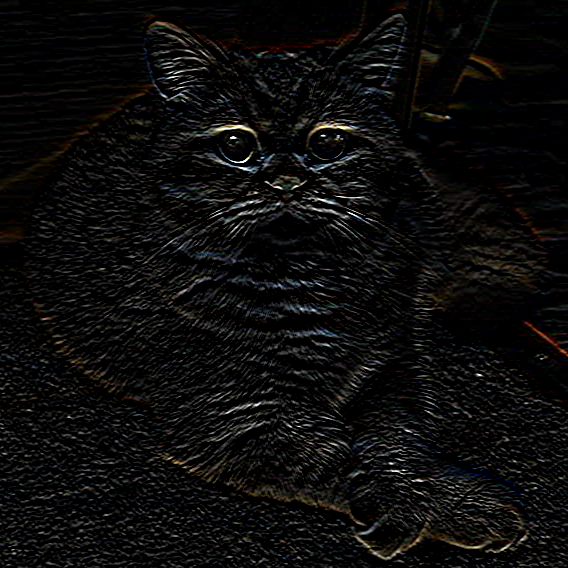

In [38]:
display(transform(image, kernel_9))

In [ ]:
#@title Решение (сначала попробуйте написать код самостоятельно)
for k in range(offset+1):
  for l in range(offset+1):
    tmp_r += red[i+k][j+l] * kernel[k][l]
    tmp_g += green[i+k][j+l] * kernel[k][l]
    tmp_b += blue[i+k][j+l] * kernel[k][l]


NameError: name 'offset' is not defined